<a href="https://colab.research.google.com/github/Oleh12342/pattern-recognition-practice/blob/model-comparison/classification-mini-project/notebooks/PR04_Kulesh_O.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Підключення Google-Drive

In [28]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [29]:
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/classification-mini-project")
DATA_DIR    = PROJECT_DIR / "data"
MODELS_DIR  = PROJECT_DIR / "models"
REPORTS_DIR = PROJECT_DIR / "reports"

MODELS_DIR.mkdir(exist_ok=True)
REPORTS_DIR.mkdir(exist_ok=True)

print(list(DATA_DIR.iterdir()))

[PosixPath('/content/drive/MyDrive/classification-mini-project/data/processed.cleveland.data'), PosixPath('/content/drive/MyDrive/classification-mini-project/data/heart_disease.csv')]


## Створення heart_disease.csv
Готового файлу heart_disease.csv не було, тому я створив його самостійно з оригінального архіву UCI Heart Disease. Використано файл processed.cleveland.data.

In [30]:
import pandas as pd

columns = [
    "age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
    "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num"
]

df = pd.read_csv(
    DATA_DIR / "processed.cleveland.data",
    header=None,
    names=columns,
    na_values="?"
)

df["target"] = (df["num"] > 0).astype(int)
df = df.drop(columns="num")

print(df.shape)
print(df["target"].value_counts())
print(df.isna().sum().sum())

df.to_csv(DATA_DIR / "heart_disease.csv", index=False)

(303, 14)
target
0    164
1    139
Name: count, dtype: int64
6


# Частина 1
Основна метрика: F1 для позитивного класу; додаткові: Recall, ROC AUC.

Імпорт бібліотек та константи

In [31]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

RANDOM_STATE = 42

numeric_columns = ["age", "trestbps", "chol", "thalach", "oldpeak"]
categorical_columns = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]
target_column = "target"

Завантаження та аудит

In [32]:
df = pd.read_csv(DATA_DIR / "heart_disease.csv")

display(df.head())
print("Розмір:", df.shape)
print("\nТипи даних:")
print(df.dtypes)
print("\nПропуски по стовпцях:")
print(df.isna().sum())
print("\nРозподіл класів:")
print(df[target_column].value_counts())
print(df[target_column].value_counts(normalize=True).round(3))
print("\nДопустимі значення target:", sorted(df[target_column].unique()))

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


Розмір: (303, 14)

Типи даних:
age         float64
sex         float64
cp          float64
trestbps    float64
chol        float64
fbs         float64
restecg     float64
thalach     float64
exang       float64
oldpeak     float64
slope       float64
ca          float64
thal        float64
target        int64
dtype: object

Пропуски по стовпцях:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64

Розподіл класів:
target
0    164
1    139
Name: count, dtype: int64
target
0    0.541
1    0.459
Name: proportion, dtype: float64

Допустимі значення target: [np.int64(0), np.int64(1)]


In [33]:
audit = pd.DataFrame({
    "Характеристика": [
        "Кількість об'єктів", "Кількість вхідних ознак",
        "Числові ознаки", "Категоріальні ознаки",
        "Кількість пропусків", "Кількість класів", "Позитивний клас"
    ],
    "Значення": [
        df.shape[0], df.shape[1] - 1,
        ", ".join(numeric_columns), ", ".join(categorical_columns),
        int(df.isna().sum().sum()), df[target_column].nunique(), 1
    ]
})
display(audit)

,Характеристика,Значення
0,Кількість об'єктів,303
1,Кількість вхідних ознак,13
2,Числові ознаки,"age, trestbps, chol, thalach, oldpeak"
3,Категоріальні ознаки,"sex, cp, fbs, restecg, exang, slope, ca, thal"
4,Кількість пропусків,6
5,Кількість класів,2
6,Позитивний клас,1


X, y і єдиний split

In [34]:
X = df.drop(columns=target_column)
y = df[target_column]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Частка класу 1 у train:", round(y_train.mean(), 3))
print("Частка класу 1 у test: ", round(y_test.mean(), 3))

Train: (242, 13)  Test: (61, 13)
Частка класу 1 у train: 0.459
Частка класу 1 у test:  0.459


Єдина схема крос-валідації


In [35]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

Препроцесинг

In [36]:
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

numeric_pipeline_scaled = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

numeric_pipeline_raw = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", "passthrough")
])

preprocessor_scaled = ColumnTransformer([
    ("num", numeric_pipeline_scaled, numeric_columns),
    ("cat", categorical_pipeline, categorical_columns)
])

preprocessor_raw = ColumnTransformer([
    ("num", numeric_pipeline_raw, numeric_columns),
    ("cat", categorical_pipeline, categorical_columns)
])

Два Pipeline логістичної регресії та порівняння за CV

In [37]:
lr_scaled = Pipeline([
    ("preprocessor", preprocessor_scaled),
    ("classifier", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
])

lr_raw = Pipeline([
    ("preprocessor", preprocessor_raw),
    ("classifier", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
])

scoring = {"f1": "f1", "roc_auc": "roc_auc", "recall": "recall"}

def run_cv(pipeline, name):
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter("always")
        res = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
        n_warn = sum("converge" in str(x.message).lower() for x in w)
    fitted = pipeline.fit(X_train, y_train)
    n_iter = int(fitted.named_steps["classifier"].n_iter_[0])
    return {
        "Модель": name,
        "CV F1": res["test_f1"].mean(), "F1 std": res["test_f1"].std(),
        "CV ROC AUC": res["test_roc_auc"].mean(), "AUC std": res["test_roc_auc"].std(),
        "CV Recall": res["test_recall"].mean(),
        "Ітерацій (train)": n_iter,
        "Попередж. збіжності": n_warn,
    }

scale_cmp = pd.DataFrame([
    run_cv(lr_raw, "LogReg без стандартизації"),
    run_cv(lr_scaled, "LogReg зі стандартизацією"),
]).round(4)
display(scale_cmp)

,Модель,CV F1,F1 std,CV ROC AUC,AUC std,CV Recall,Ітерацій (train),Попередж. збіжності
0,LogReg без стандартизації,0.8245,0.0069,0.8997,0.0157,0.7834,1238,0
1,LogReg зі стандартизацією,0.8245,0.0069,0.9025,0.0144,0.7834,18,0


L1- і L2-регуляризація

In [38]:
param_grid = [
    {"classifier__penalty": ["l1", "l2"],
     "classifier__C": [0.01, 0.1, 1, 10, 100]}
]

lr_grid_pipe = Pipeline([
    ("preprocessor", preprocessor_scaled),
    ("classifier", LogisticRegression(solver="liblinear", max_iter=2000, random_state=RANDOM_STATE))
])

grid_lr = GridSearchCV(
    lr_grid_pipe, param_grid,
    scoring="f1", cv=cv, n_jobs=-1, refit=True,
    return_train_score=False
)
grid_lr.fit(X_train, y_train)

print("Найкращі параметри:", grid_lr.best_params_)
print("Найкращий CV F1:", round(grid_lr.best_score_, 4))

lr_results = (pd.DataFrame(grid_lr.cv_results_)
    [["param_classifier__penalty", "param_classifier__C",
      "mean_test_score", "std_test_score", "rank_test_score"]]
    .rename(columns={
        "param_classifier__penalty": "penalty",
        "param_classifier__C": "C",
        "mean_test_score": "CV F1",
        "std_test_score": "CV F1 std",
        "rank_test_score": "rank"})
    .sort_values("rank"))
display(lr_results.round(4))

Найкращі параметри: {'classifier__C': 10, 'classifier__penalty': 'l2'}
Найкращий CV F1: 0.8363


,penalty,C,CV F1,CV F1 std,rank
7,l2,10.00,0.8363,0.0127,1
8,l1,100.00,0.8363,0.0127,1
9,l2,100.00,0.8363,0.0127,1
6,l1,10.00,0.8321,0.0108,4
5,l2,1.00,0.8245,0.0069,5
3,l2,0.10,0.8140,0.0299,6
4,l1,1.00,0.8123,0.0173,7
2,l1,0.10,0.7926,0.0306,8
1,l2,0.01,0.7658,0.0171,9
0,l1,0.01,0.0000,0.0000,10


Графік залежності CV F1 від C

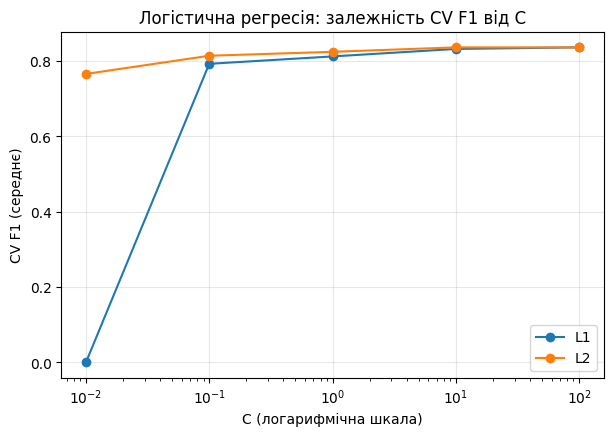

In [39]:
plt.figure(figsize=(7, 4.5))
for pen in ["l1", "l2"]:
    sub = lr_results[lr_results["penalty"] == pen].sort_values("C")
    plt.plot(sub["C"].astype(float), sub["CV F1"], marker="o", label=pen.upper())
plt.xscale("log")
plt.xlabel("C (логарифмічна шкала)")
plt.ylabel("CV F1 (середнє)")
plt.title("Логістична регресія: залежність CV F1 від C")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Топ-5 коефіцієнтів найкращої моделі

In [40]:
best_lr = grid_lr.best_estimator_
feature_names = best_lr.named_steps["preprocessor"].get_feature_names_out()
coefs = best_lr.named_steps["classifier"].coef_[0]

coef_df = pd.DataFrame({
    "Ознака": feature_names,
    "Коефіцієнт": coefs,
    "|Коефіцієнт|": np.abs(coefs)
}).sort_values("|Коефіцієнт|", ascending=False)

display(coef_df.head(5).round(4))

,Ознака,Коефіцієнт,|Коефіцієнт|
21,cat__ca_0.0,-1.9262,1.9262
10,cat__cp_4.0,1.1886,1.1886
27,cat__thal_7.0,0.9779,0.9779
7,cat__cp_1.0,-0.8921,0.8921
5,cat__sex_0.0,-0.8802,0.8802


## Висновок
Побудовано Pipeline (імпутація, стандартизація, one-hot-кодування) і досліджено логістичну регресію за 5-кратною StratifiedKFold лише на train; тестова вибірка не використовувалася.

- **Масштабування:** CV F1 (0,8245) і Recall (0,7834) не змінилися, ROC AUC майже однаковий (0,9025 проти 0,8997). Різниця у збіжності: 18 ітерацій зі стандартизацією проти 1238 без неї, тому далі використовуємо стандартизацію.
- **Регуляризація:** найкраща конфігурація за CV: L2, C = 10 (CV F1 = 0,8363, std = 0,0127). За C = 0,01 L1 занулює всі коефіцієнти (F1 = 0, недонавчання), а за C ≥ 10 якість виходить на плато.
- **Коефіцієнти:** найбільші за модулем мають ca = 0 (-1,93), cp = 4 (+1,19), thal = 7 (+0,98), cp = 1 (-0,89), sex = ` (-0,88). Вони описують закономірності в даних, але не доводять причинного впливу.